# Génération d'image & jeu avec le gradient

L'idée est de récupérer une architecture pré-entrainée et d'aller jouer avec. Deux options assez simples sont envisageables:
1. Les approches *deepdream* : [github](https://github.com/google/deepdream/tree/master); [LeMonde](https://www.lemonde.fr/pixels/article/2015/07/09/on-a-teste-pour-vous-deep-dream-la-machine-a-reves-psychedeliques-de-google_4675562_4408996.html)
1. Les approches *style/content*, dites aussi transfert de style [github](https://github.com/Raed-Alshehri/Art_Generation_Neural_Style_Transfer). Si j'ai une image A qui m'interesse pour son contenu et une image B (i.e. un Van Gogh ou Munch) qui m'interesse pour son style, suis-je capable de construire une version A' qui prend le style de B?

Dans tous les cas, il faut récupérer un modèle (par exemple GoogLeNet) pré-entrainé puis récupérer et contraindre des couches intermédiaires (=définir une loss) puis ensuite activer le gradient sur l'entrée et laisser dériver l'image


In [1]:
# importation d'un googlenet
# affichage des différentes couches => ce sera critique pour venir s'accrocher sur le réseau

import torch
from torchvision.models import googlenet, GoogLeNet_Weights

model = googlenet(weights=GoogLeNet_Weights.IMAGENET1K_V1)
model.eval()

GoogLeNet(
  (conv1): BasicConv2d(
    (conv): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (bn): BatchNorm2d(64, eps=0.001, momentum=0.1, affine=True, track_running_stats=True)
  )
  (maxpool1): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=True)
  (conv2): BasicConv2d(
    (conv): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
    (bn): BatchNorm2d(64, eps=0.001, momentum=0.1, affine=True, track_running_stats=True)
  )
  (conv3): BasicConv2d(
    (conv): Conv2d(64, 192, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (bn): BatchNorm2d(192, eps=0.001, momentum=0.1, affine=True, track_running_stats=True)
  )
  (maxpool2): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=True)
  (inception3a): Inception(
    (branch1): BasicConv2d(
      (conv): Conv2d(192, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn): BatchNorm2d(64, eps=0.001, momentum=0.1, affine=True, track

## A. Classification d'image

Vérifier que le réseau marche bien en classification d'image

1. Charger une image
1. Appliquer le classifieur
1. Télécharger la signification des étiquettes

In [2]:
# Download an example image from the pytorch website
import urllib
url, filename = ("https://github.com/pytorch/hub/raw/master/images/dog.jpg", "img/dog.jpg")
try: urllib.URLopener().retrieve(url, filename)
except: urllib.request.urlretrieve(url, filename)

In [3]:
# sample execution (requires torchvision)
from PIL import Image
from torchvision import transforms

# load image
input_image = Image.open(filename)
preprocess = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])
input_tensor = preprocess(input_image)
input_batch = input_tensor.unsqueeze(0) # create a mini-batch as expected by the model

# move the input and model to GPU for speed if available
if torch.cuda.is_available():
    input_batch = input_batch.to('cuda')
    model.to('cuda')

with torch.no_grad():
    output = model(input_batch)
# Tensor of shape 1000, with confidence scores over ImageNet's 1000 classes
print(output[0])
# The output has unnormalized scores. To get probabilities, you can run a softmax on it.
probabilities = torch.nn.functional.softmax(output[0], dim=0)
print(probabilities)

tensor([ 3.4785e-02, -2.2930e-01, -3.2345e-01,  5.6524e-02,  1.1326e-01,
        -2.8245e-01,  6.1733e-01,  6.2308e-02,  9.4706e-01, -1.4972e+00,
        -5.5112e-01, -3.4199e-02, -1.2638e+00, -3.2188e-02,  5.3419e-01,
         1.8680e-01,  4.9378e-01, -2.8233e-01, -2.7230e-01, -2.6111e-01,
        -3.3323e-01, -7.6593e-02,  6.7301e-02, -5.7032e-01, -5.3223e-01,
        -4.9684e-02,  7.1982e-01,  1.1620e+00,  5.1530e-01,  1.3021e+00,
         6.8994e-01,  5.5600e-01,  1.3222e-01, -7.1020e-01, -5.0299e-01,
        -2.4432e-01, -5.9986e-01,  1.9393e-01, -3.2075e-01,  6.1717e-01,
         2.9619e-01, -2.4272e-01,  1.8611e-01, -4.5770e-01,  1.5218e-01,
        -6.8320e-01,  9.8977e-01,  6.1453e-01, -1.2938e+00, -4.6704e-01,
        -7.0944e-02,  2.6083e-04,  3.7347e-01,  1.8133e-01,  8.5789e-01,
         1.0047e+00, -3.0300e-01,  1.9940e-02,  7.7358e-02,  8.1188e-01,
         7.7604e-01, -7.0548e-01, -2.2685e-01, -2.5820e-01,  1.5494e-01,
        -4.5728e-01,  7.8210e-01,  1.4199e-01,  1.0

In [4]:
# Download ImageNet labels (compatible Windows / Mac / Linux)
import urllib.request
urllib.request.urlretrieve(
    "https://raw.githubusercontent.com/pytorch/hub/master/imagenet_classes.txt",
    "imagenet_classes.txt",
)

('imagenet_classes.txt', <http.client.HTTPMessage at 0x206cd88fa10>)

In [5]:
# Read the categories
with open("imagenet_classes.txt", "r") as f:
    categories = [s.strip() for s in f.readlines()]
# Show top categories per image
top5_prob, top5_catid = torch.topk(probabilities, 5)
for i in range(top5_prob.size(0)):
    print(categories[top5_catid[i]], top5_prob[i].item())

Samoyed 0.9379345178604126
Pomeranian 0.008287554606795311
Great Pyrenees 0.005583279766142368
Arctic fox 0.005528860259801149
white wolf 0.004737776704132557


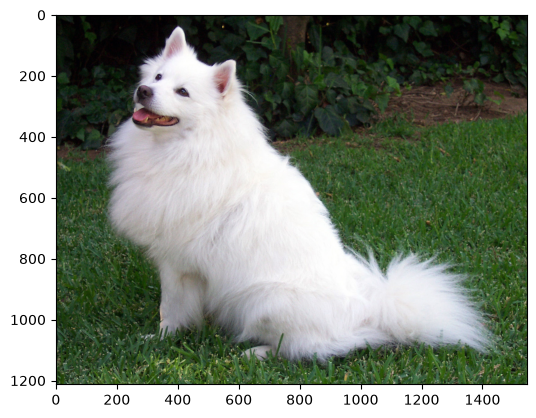

In [6]:
import numpy as np
import matplotlib.pyplot as plt

plt.imshow(input_image)

## B. Deepdream

1. Charger l'image + activer le gradient
1. La passer dans le réseau et récupérer une couche cachée
1. Définir une loss sur cette couche
1. Rétro-propager l'erreur

In [7]:
import torch
import torch.nn.functional as F
from torchvision import models, transforms
from PIL import Image
import matplotlib.pyplot as plt
import copy

# --- 2. Charger une image PIL et la prétraiter ---
def load_image(path, max_size=500):
    image = Image.open(path).convert("RGB")
    transform = transforms.Compose([
        transforms.Resize(max_size),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406],
                             std=[0.229, 0.224, 0.225])
    ])
    return transform(image).unsqueeze(0)


device = next(model.parameters()).device  # même device que le modèle (CPU ou GPU)
img = load_image("img/dog.jpg").to(device)
img_orig = copy.deepcopy(img)


On va utiliser les *hooks* = récupération très simplifiée d'information à l'intérieur du réseau
1. On *pose* le crochet
1. On fait le forward
1. On a l'information dans une structure de données, on va pouvoir créer notre loss!

In [8]:

# --- 3. Choisir une couche cible ---
layer_name = 'inception4b'  # peut être 'inception3a', 'inception4d', 'inception4c' etc.

# --- 4. Extraire les activations intermédiaires ---
activations = {}

# Crochet
def hook_fn(module, input, output):
    activations['feat'] = output

# Récupérer le module voulu
target_layer = dict(model.named_modules())[layer_name]
hook = target_layer.register_forward_hook(hook_fn)

# --- 5. DeepDream : ascension de gradient sur l’image ---
img.requires_grad_(True)
optimizer = torch.optim.Adam([img], lr=0.1) # jouer avec le learning rate + nb itération

for i in range(30):  # nombre d’itérations
    optimizer.zero_grad()
    model(img)
    loss = -activations['feat'].norm()  # maximise la norme des activations ATTENTION à bien mettre un moins !
    loss.backward()
    optimizer.step()

    # Optionnel : normaliser légèrement les pixels pour la stabilité
    img.data = torch.clamp(img.data, -2, 2)

    if i % 5 == 0:
        print(f"Iteration {i}, Loss = {loss.item():.2f}")

hook.remove()


Iteration 0, Loss = -477.73
Iteration 5, Loss = -935.05
Iteration 10, Loss = -1219.26
Iteration 15, Loss = -1409.54
Iteration 20, Loss = -1553.94
Iteration 25, Loss = -1669.72


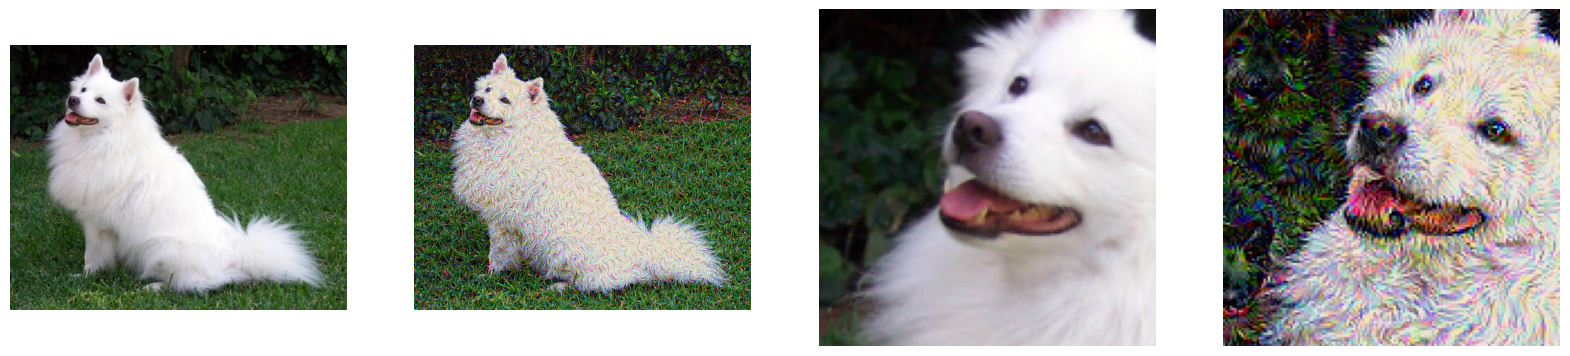

In [9]:

# --- 6. Convertir l’image en format affichable ---
def deprocess(tensor):
    tensor = tensor.detach().cpu().squeeze(0)
    tensor = tensor * torch.tensor([0.229, 0.224, 0.225]).view(3,1,1)
    tensor = tensor + torch.tensor([0.485, 0.456, 0.406]).view(3,1,1)
    tensor = torch.clamp(tensor, 0, 1)
    return transforms.ToPILImage()(tensor)

dream_img = deprocess(img)
img_orig2  = deprocess(img_orig)
dream_img_c = dream_img.crop((50, 50, 200, 200))
img_orig_c = img_orig2.crop((50, 50, 200, 200))


plt.figure(figsize=(20,5))

plt.subplot(1,4,1)
plt.imshow(img_orig2)
plt.axis("off")

plt.subplot(1,4,2)
plt.imshow(dream_img)
plt.axis("off")

plt.subplot(1,4,3)
plt.imshow(img_orig_c)
plt.axis("off")

plt.subplot(1,4,4)
plt.imshow(dream_img_c)
plt.axis("off")


plt.show()


## C. Reconstruction d'image

1. A *encoder* (=forward) une image dans un réseau 
1. Isoler une représentation de cette image... Permettra-t-elle de reconstruire l'image?
1. Partir d'une image aléatoire (bruit blanc gaussien) avec gradient activé
1. Minimiser la distance au contenu encodé dans l'embedding

On va travailler avec le même réseau. Mais on introduit différentes optimisation pour aller plus vite en calcul.

In [10]:
from torch.optim.lr_scheduler import OneCycleLR # pour accélérer


print("La version de torch est : ",torch.__version__)
print("Le calcul GPU est disponible ? ", torch.cuda.is_available())
# pour les possesseurs de mac M1 avec la dernière version de pytorch:
print("Le calcul GPU est disponible ? ", torch.backends.mps.is_available())

device = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")

La version de torch est :  2.11.0+cu128
Le calcul GPU est disponible ?  True
Le calcul GPU est disponible ?  False


Le transfert de style sera à faire par vous même... Mais afin de simplifier les choses, je vous propose un code permettant la reconstruction d'une image à partir d'un embedding

In [11]:
img   = load_image("img/dog.jpg").to(device)

layer_content = 'inception3a'  # la première (bon encodage du contenu)
activations = {}

# Crochet
def hook_fn(module, input, output):
    activations['feat'] = output
target_layer = dict(model.named_modules())[layer_content]
hook = target_layer.register_forward_hook(hook_fn)


# target = une couche de l'encodage d'une image
with torch.no_grad():
    model(img)
    target = activations['feat'].clone()
    print("dimension de l'embedding : ", target.shape)


# Générer une image aléatoire
noise = torch.randn_like(img).to(device) #*0.1

# --- 5. Generation d'image : minimiser la norme entre les embeddings ---
noise.requires_grad_(True)

nepoch = 1000
max_lr=5e-1 # version optimisée OneCycle
optimizer = torch.optim.AdamW([noise], lr=max_lr)
scheduler = OneCycleLR(optimizer, max_lr=max_lr, steps_per_epoch=1, epochs=nepoch)

# optimizer = torch.optim.Adam([noise], lr=0.05) # jouer avec le learning rate + nb itération

for i in range(nepoch):  # nombre d’itérations
    optimizer.zero_grad()
    model(noise)
    loss = (target-activations['feat']).norm()  
    loss.backward()
    optimizer.step()
    scheduler.step()

    # Optionnel : normaliser légèrement les pixels pour la stabilité
    noise.data = torch.clamp(noise.data, -2, 2)

    if i % 5 == 0:
        print(f"Iteration {i}, Loss = {loss.item():.2f}")

    # if i % 200 == 0:  # Si vous voulez voir la progression
    #     dream_img = deprocess(noise.to("cpu"))
    #     dream_img.save("save/image"+str(i)+".jpg")

hook.remove()


dimension de l'embedding :  torch.Size([1, 256, 62, 79])
Iteration 0, Loss = 863.28
Iteration 5, Loss = 735.19
Iteration 10, Loss = 662.65
Iteration 15, Loss = 610.65
Iteration 20, Loss = 570.28
Iteration 25, Loss = 537.79
Iteration 30, Loss = 510.83
Iteration 35, Loss = 488.08
Iteration 40, Loss = 467.91
Iteration 45, Loss = 449.77
Iteration 50, Loss = 432.79
Iteration 55, Loss = 416.69
Iteration 60, Loss = 401.36
Iteration 65, Loss = 386.38
Iteration 70, Loss = 371.68
Iteration 75, Loss = 357.22
Iteration 80, Loss = 343.01
Iteration 85, Loss = 329.31
Iteration 90, Loss = 316.15
Iteration 95, Loss = 304.09
Iteration 100, Loss = 293.70
Iteration 105, Loss = 285.75
Iteration 110, Loss = 281.17
Iteration 115, Loss = 279.57
Iteration 120, Loss = 278.50
Iteration 125, Loss = 278.69
Iteration 130, Loss = 279.56
Iteration 135, Loss = 281.28
Iteration 140, Loss = 282.34
Iteration 145, Loss = 285.02
Iteration 150, Loss = 285.81
Iteration 155, Loss = 289.96
Iteration 160, Loss = 292.84
Iteratio

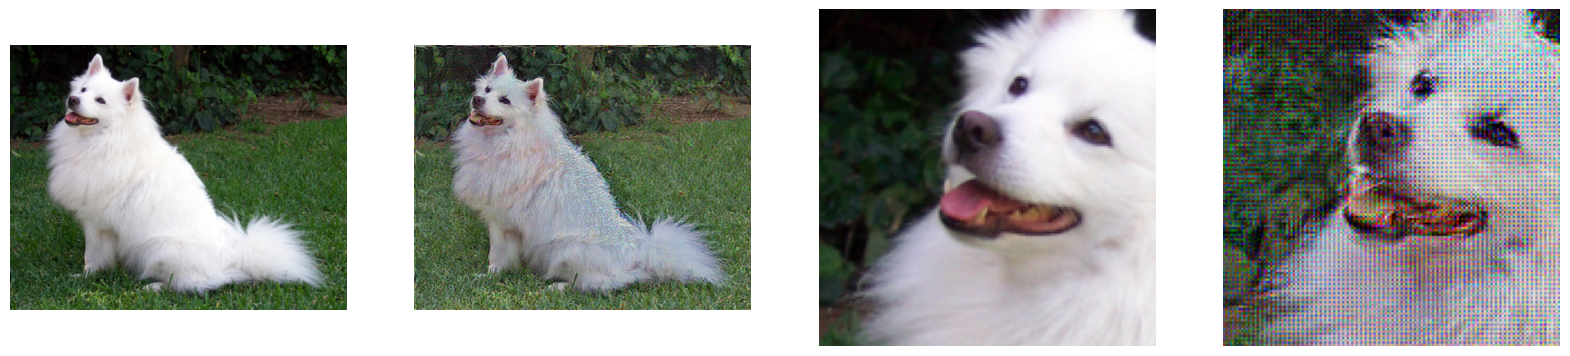

In [12]:

# --- 6. Convertir l’image en format affichable ---

dream_img = deprocess(noise.to("cpu"))
img_orig2  = deprocess(img.to("cpu"))
dream_img_c = dream_img.crop((50, 50, 200, 200))
img_orig_c = img_orig2.crop((50, 50, 200, 200))


plt.figure(figsize=(20,5))

plt.subplot(1,4,1)
plt.imshow(img_orig2)
plt.axis("off")

plt.subplot(1,4,2)
plt.imshow(dream_img)
plt.axis("off")

plt.subplot(1,4,3)
plt.imshow(img_orig_c)
plt.axis("off")

plt.subplot(1,4,4)
plt.imshow(dream_img_c)
plt.axis("off")


plt.show()


## D. Transfert de style

Le transfert de style [lien](https://github.com/Raed-Alshehri/Art_Generation_Neural_Style_Transfer) consiste:
1. A *encoder* (=forward) deux images dans un réseau 
1. Isoler deux représentations à deux étages différents (couche intermédiaire pour le contenu, couche profonde pour le style)
1. Partir d'une image aléatoire (bruit blanc gaussien) avec gradient activé
1. Minimiser la distance à la fois au contenu et au style (= 2 normes à pondérer)

On va travailler avec le même réseau

A vous de jouer pour le transfert

In [13]:
img   = load_image("img/dog.jpg").to(device)
style = load_image("img/vg.jpg").to(device)
model = model.to(device)

In [24]:
# --- 3. Choisir une couche cible ---
layer_content = 'inception3a'  # la première
layer_style   = 'inception5a'  # la dernière

###  TODO 

# --- 4. chopper les hooks 
activation = {}

def make_hook(clef):
    def hook_fn(module, input, output):
        activation[clef] = output
    return hook_fn

modules = dict(model.named_modules())
hook_content = modules[layer_content].register_forward_hook(make_hook('content'))
hook_style   = modules[layer_style].register_forward_hook(make_hook('style'))

# Matrice de Gram : corrélations entre canaux
def gram(x):
    _, C, H, W = x.shape
    f = x.view(C, H * W)
    return (f @ f.T) / (C * H * W)

# Cibles fixes : contenu du chien, style de Van Gogh
with torch.no_grad():
    model(img)
    target_content = activation['content'].clone()
    model(style)
    target_gram = gram(activation['style']).clone()

# Image à optimiser (bruit comme en section C)
noise = torch.randn_like(img).to(device)
noise.requires_grad_(True)

nepoch = 500
max_lr = 5e-2
alpha, beta = 1, 1e4   # poids contenu / style, à ajuster

optimizer = torch.optim.AdamW([noise], lr=max_lr)
scheduler = OneCycleLR(optimizer, max_lr=max_lr, steps_per_epoch=1, epochs=nepoch)

for i in range(nepoch):
    optimizer.zero_grad()
    model(noise)

    loss_content = (target_content - activation['content']).norm()
    loss_style   = (target_gram - gram(activation['style'])).norm()
    loss = alpha * loss_content + beta * loss_style

    loss.backward()
    optimizer.step()
    scheduler.step()

    noise.data = torch.clamp(noise.data, -2, 2)

    if i % 20 == 0:
        print(f"Iter {i}, content = {loss_content.item():.2f}, "
              f"style = {loss_style.item():.4f}, total = {loss.item():.2f}")

hook_content.remove()
hook_style.remove()


Iter 0, content = 864.13, style = 0.0288, total = 1152.41
Iter 20, content = 834.60, style = 0.0191, total = 1025.16
Iter 40, content = 774.66, style = 0.0143, total = 917.85
Iter 60, content = 699.97, style = 0.0071, total = 770.78
Iter 80, content = 620.57, style = 0.0061, total = 681.18
Iter 100, content = 574.31, style = 0.0059, total = 633.61
Iter 120, content = 548.24, style = 0.0062, total = 610.28
Iter 140, content = 525.67, style = 0.0059, total = 584.39
Iter 160, content = 503.85, style = 0.0057, total = 560.90
Iter 180, content = 481.84, style = 0.0052, total = 533.76
Iter 200, content = 462.02, style = 0.0050, total = 511.85
Iter 220, content = 448.55, style = 0.0055, total = 503.20
Iter 240, content = 433.87, style = 0.0052, total = 486.19
Iter 260, content = 420.07, style = 0.0041, total = 460.86
Iter 280, content = 406.05, style = 0.0039, total = 445.24
Iter 300, content = 395.23, style = 0.0036, total = 431.62
Iter 320, content = 386.39, style = 0.0034, total = 420.77
I

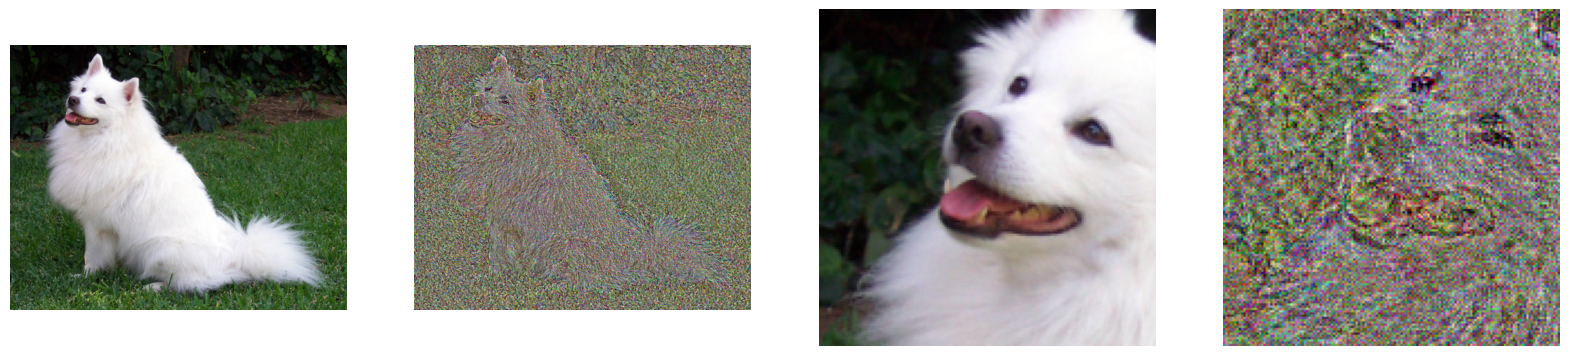

In [25]:

# --- 6. Convertir l’image en format affichable ---

dream_img = deprocess(noise.to("cpu"))
img_orig2  = deprocess(img.to("cpu"))
dream_img_c = dream_img.crop((50, 50, 200, 200))
img_orig_c = img_orig2.crop((50, 50, 200, 200))


plt.figure(figsize=(20,5))

plt.subplot(1,4,1)
plt.imshow(img_orig2)
plt.axis("off")

plt.subplot(1,4,2)
plt.imshow(dream_img)
plt.axis("off")

plt.subplot(1,4,3)
plt.imshow(img_orig_c)
plt.axis("off")

plt.subplot(1,4,4)
plt.imshow(dream_img_c)
plt.axis("off")


plt.show()


# Construction du sujet à partir de la correction

In [ ]:
###  TODO )"," TODO ",\
    txt, flags=re.DOTALL))
f2.close()

### </CORRECTION> ###